In [1]:
from pathlib import Path
# Check the folder where Jupyter is currently running
print("Current folder:", Path.cwd())

# Our notebook is inside notebooks/, and CSV files are inside data/
DATA_DIR = Path("Supply_Chain_Optimization_data")

# Check whether the data folder exists
print("Data folder exists:", DATA_DIR.exists())

# List all CSV files found in the folder
csv_files = sorted(DATA_DIR.glob("*.csv"))

for file in csv_files:
    print(file.name)

Current folder: C:\Users\Dell
Data folder exists: True
olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_orders_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("Supply_Chain_Optimization_data")

orders = pd.read_csv(DATA_DIR / "olist_orders_dataset.csv")
order_items = pd.read_csv(DATA_DIR / "olist_order_items_dataset.csv")
customers = pd.read_csv(DATA_DIR / "olist_customers_dataset.csv")
sellers = pd.read_csv(DATA_DIR / "olist_sellers_dataset.csv")
reviews = pd.read_csv(DATA_DIR / "olist_order_reviews_dataset.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [4]:
datasets = {
    "Orders": orders,
    "Order Items": order_items,
    "Customers": customers,
    "Sellers": sellers,
    "Reviews": reviews
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")

Orders: 99,441 rows, 8 columns
Order Items: 112,650 rows, 7 columns
Customers: 99,441 rows, 5 columns
Sellers: 3,095 rows, 4 columns
Reviews: 99,224 rows, 7 columns


In [5]:
orders.head()


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [6]:
orders.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [7]:
print("Missing values:")
print(orders.isnull().sum())

print("\nDuplicate rows:", orders.duplicated().sum())
print("Unique orders:", orders["order_id"].nunique())

Missing values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Duplicate rows: 0
Unique orders: 99441


In [8]:
orders_clean = orders.copy()

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders_clean[col] = pd.to_datetime(
        orders_clean[col], errors="coerce"
    )

print("Date conversion completed!")
orders_clean[date_columns].dtypes

Date conversion completed!


order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

In [9]:
status_summary = (
    orders_clean["order_status"]
    .value_counts(dropna=False)
    .rename_axis("Order Status")
    .reset_index(name="Number of Orders")
)

status_summary["Percentage"] = (
    status_summary["Number of Orders"]
    / len(orders_clean) * 100
).round(2)

status_summary

,Order Status,Number of Orders,Percentage
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


In [10]:
missing_delivery_analysis = (
    orders_clean.groupby("order_status")
    .agg(
        total_orders=("order_id", "count"),
        missing_delivery_dates=(
            "order_delivered_customer_date",
            lambda s: s.isna().sum()
        )
    )
    .reset_index()
)

missing_delivery_analysis

,order_status,total_orders,missing_delivery_dates
0,approved,2,2
1,canceled,625,619
2,created,5,5
3,delivered,96478,8
4,invoiced,314,314
5,processing,301,301
6,shipped,1107,1107
7,unavailable,609,609


In [11]:
delivered = orders_clean[
    (orders_clean["order_status"] == "delivered")
    & (orders_clean["order_delivered_customer_date"].notna())
    & (orders_clean["order_estimated_delivery_date"].notna())
].copy()

# Actual time from purchase to customer delivery
delivered["delivery_time_days"] = (
    delivered["order_delivered_customer_date"]
    - delivered["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Positive = late; negative = early
delivered["delay_days"] = (
    delivered["order_delivered_customer_date"]
    - delivered["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

# On time includes delivery exactly on the estimated date
delivered["delivery_performance"] = np.where(
    delivered["delay_days"] <= 0,
    "On Time or Early",
    "Late"
)

print("Eligible delivered orders:", len(delivered))
delivered[
    [
        "order_id",
        "delivery_time_days",
        "delay_days",
        "delivery_performance"
    ]
].head()

Eligible delivered orders: 96470


,order_id,delivery_time_days,delay_days,delivery_performance
0,e481f51cbdc54678b7cc49136f2d6af7,8.436574,-7.107488,On Time or Early
1,53cdb2fc8bc7dce0b6741e2150273451,13.782037,-5.355729,On Time or Early
2,47770eb9100c2d0c44946d9cf07ec65d,9.394213,-17.245498,On Time or Early
3,949d5b44dbf5de918fe9c16f97b45f8a,13.208750,-12.980069,On Time or Early
4,ad21c59c0840e6cb83a9ceb5573f8159,2.873877,-9.238171,On Time or Early


In [12]:
total_delivered = len(delivered)

on_time_count = (
    delivered["delivery_performance"] == "On Time or Early"
).sum()

late_count = (
    delivered["delivery_performance"] == "Late"
).sum()

delivery_kpis = pd.DataFrame({
    "Metric": [
        "Eligible delivered orders",
        "On-time or early orders",
        "Late orders",
        "On-time delivery rate (%)",
        "Late delivery rate (%)",
        "Average delivery time (days)",
        "Average delay (days)",
        "Median delivery time (days)"
    ],
    "Value": [
        total_delivered,
        on_time_count,
        late_count,
        round(on_time_count / total_delivered * 100, 2)
            if total_delivered else np.nan,
        round(late_count / total_delivered * 100, 2)
            if total_delivered else np.nan,
        round(delivered["delivery_time_days"].mean(), 2),
        round(delivered.loc[
            delivered["delay_days"] > 0, "delay_days"
        ].mean(), 2),
        round(delivered["delivery_time_days"].median(), 2)
    ]
})

delivery_kpis

,Metric,Value
0,Eligible delivered orders,96470.00
1,On-time or early orders,88644.00
2,Late orders,7826.00
3,On-time delivery rate (%),91.89
4,Late delivery rate (%),8.11
5,Average delivery time (days),12.56
6,Average delay (days),9.55
7,Median delivery time (days),10.22


In [13]:
# Select customer location information
customer_locations = customers[
    ["customer_id", "customer_state"]
].copy()

# Join customer state to our eligible delivered orders
regional_data = delivered.merge(
    customer_locations,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print("Rows before join:", len(delivered))
print("Rows after join:", len(regional_data))
print("Missing customer states:", regional_data["customer_state"].isna().sum())

Rows before join: 96470
Rows after join: 96470
Missing customer states: 0


In [14]:
regional_performance = (
    regional_data.groupby("customer_state")
    .agg(
        total_orders=("order_id", "nunique"),
        late_orders=(
            "delivery_performance",
            lambda s: (s == "Late").sum()
        ),
        avg_delivery_days=("delivery_time_days", "mean"),
        avg_delay_days=("delay_days", "mean")
    )
    .reset_index()
)

regional_performance["late_rate_pct"] = (
    regional_performance["late_orders"]
    / regional_performance["total_orders"] * 100
).round(2)

regional_performance = regional_performance.sort_values(
    "late_rate_pct", ascending=False
)

regional_performance.head(10)

,customer_state,total_orders,late_orders,avg_delivery_days,avg_delay_days,late_rate_pct
1,AL,397,95,24.543855,-8.032059,23.93
9,MA,717,141,21.572976,-8.887844,19.67
16,PI,476,76,19.457098,-10.629538,15.97
5,CE,1279,196,21.266579,-10.110007,15.32
24,SE,335,51,21.519788,-9.328641,15.22
4,BA,3256,457,19.335466,-10.099073,14.04
18,RJ,12350,1664,15.309438,-11.054735,13.47
26,TO,274,35,17.658063,-11.439738,12.77
13,PA,946,117,23.772917,-13.386288,12.37
7,ES,1995,244,15.789307,-9.797109,12.23


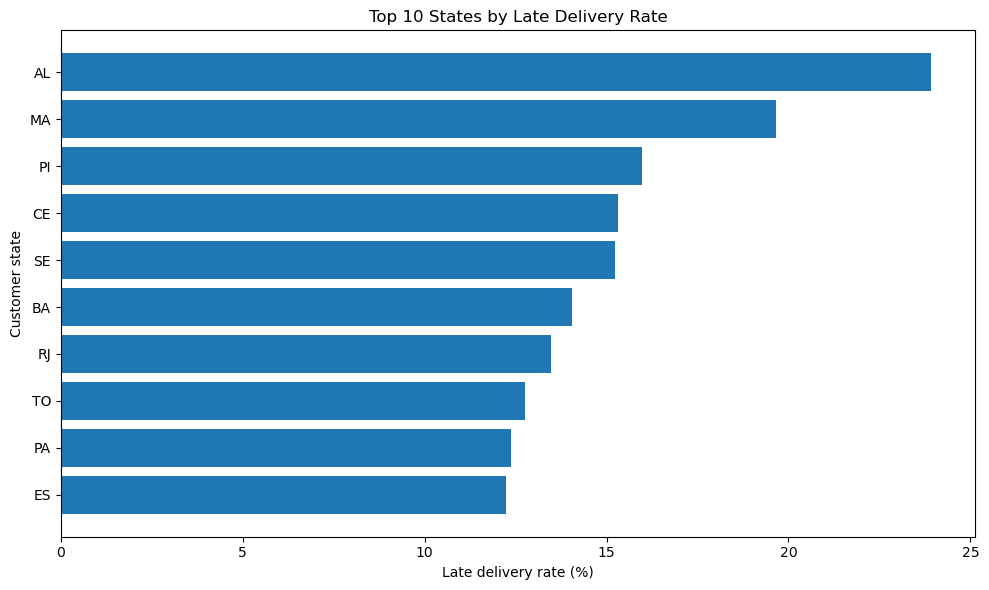

In [16]:
top_states = regional_performance.head(10).sort_values(
    "late_rate_pct"
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_states["customer_state"],
    top_states["late_rate_pct"]
)

plt.xlabel("Late delivery rate (%)")
plt.ylabel("Customer state")
plt.title("Top 10 States by Late Delivery Rate")
plt.tight_layout()
plt.show()

In [20]:
late_only = regional_data[
    regional_data["delivery_performance"] == "Late"
].copy()

late_delay_by_state = (
    late_only.groupby("customer_state")
    .agg(
        late_orders=("order_id", "nunique"),
        avg_late_delay_days=("delay_days", "mean")
    )
    .reset_index()
)

regional_performance = regional_performance.merge(
    late_delay_by_state,
    on="customer_state",
    how="left",
    validate="one_to_one"
)

regional_performance["avg_late_delay_days"] = (
    regional_performance["avg_late_delay_days"].round(2)
)

regional_performance = regional_performance.sort_values(
    "late_rate_pct", ascending=False
)

regional_performance.head(10)

,customer_state,total_orders,late_orders_x,avg_delivery_days,avg_delay_days,late_rate_pct,late_orders_y,avg_late_delay_days
0,AL,397,95,24.543855,-8.032059,23.93,95,9.25
1,MA,717,141,21.572976,-8.887844,19.67,141,9.97
2,PI,476,76,19.457098,-10.629538,15.97,76,12.30
3,CE,1279,196,21.266579,-10.110007,15.32,196,14.33
4,SE,335,51,21.519788,-9.328641,15.22,51,16.89
5,BA,3256,457,19.335466,-10.099073,14.04,457,11.10
6,RJ,12350,1664,15.309438,-11.054735,13.47,1664,12.85
7,TO,274,35,17.658063,-11.439738,12.77,35,5.65
8,PA,946,117,23.772917,-13.386288,12.37,117,12.30
9,ES,1995,244,15.789307,-9.797109,12.23,244,10.60


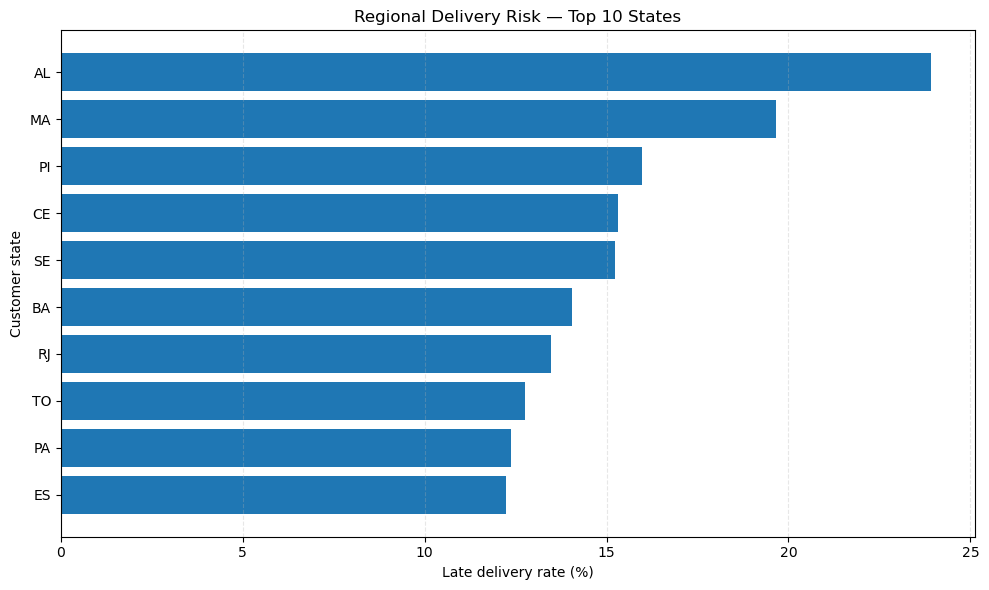

In [22]:
top_states = (
    regional_performance.head(10)
    .sort_values("late_rate_pct")
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_states["customer_state"],
    top_states["late_rate_pct"]
)

plt.xlabel("Late delivery rate (%)")
plt.ylabel("Customer state")
plt.title("Regional Delivery Risk — Top 10 States")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
# Step 1: Keep the required columns
seller_orders = order_items[
    ["order_id", "seller_id"]
].copy()

# Step 2: Remove duplicate order-seller combinations
seller_orders = seller_orders.drop_duplicates(
    subset=["order_id", "seller_id"]
)

# Step 3: Add delivery performance information
seller_performance_data = seller_orders.merge(
    delivered[
        [
            "order_id",
            "delivery_time_days",
            "delay_days",
            "delivery_performance"
        ]
    ],
    on="order_id",
    how="inner",
    validate="many_to_one"
)

# Step 4: Add seller location
seller_locations = sellers[
    ["seller_id", "seller_state"]
].copy()

seller_performance_data = seller_performance_data.merge(
    seller_locations,
    on="seller_id",
    how="left",
    validate="many_to_one"
)

# Step 5: Check the result
print("Unique order-seller pairs:", len(seller_orders))
print("Rows in analysis:", len(seller_performance_data))
print(
    "Missing seller states:",
    seller_performance_data["seller_state"].isna().sum()
)

seller_performance_data.head()

Unique order-seller pairs: 100010
Rows in analysis: 97811
Missing seller states: 0


,order_id,seller_id,delivery_time_days,delay_days,delivery_performance,seller_state
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,7.614421,-8.011250,On Time or Early,SP
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,16.216181,-2.330278,On Time or Early,SP
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,7.948437,-13.444954,On Time or Early,MG
3,00024acbcdf0a6daa1e931b038114c75,9d7a1d34a5052409006425275ba1c2b4,6.147269,-5.435660,On Time or Early,SP
4,00042b26cf59d7ce69dfabb4e55b4fd9,df560393f3a51e74553ab94004ba5c87,25.114352,-15.303808,On Time or Early,PR


In [29]:
print("Column names:")
print(seller_performance_data.columns.tolist())

print("\nData types:")
print(seller_performance_data.dtypes)

print("\nFirst 5 rows:")
display(seller_performance_data.head())

Column names:
['order_id', 'seller_id', 'delivery_time_days', 'delay_days', 'delivery_performance', 'seller_state']

Data types:
order_id                 object
seller_id                object
delivery_time_days      float64
delay_days              float64
delivery_performance     object
seller_state             object
dtype: object

First 5 rows:


,order_id,seller_id,delivery_time_days,delay_days,delivery_performance,seller_state
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,7.614421,-8.011250,On Time or Early,SP
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,16.216181,-2.330278,On Time or Early,SP
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,7.948437,-13.444954,On Time or Early,MG
3,00024acbcdf0a6daa1e931b038114c75,9d7a1d34a5052409006425275ba1c2b4,6.147269,-5.435660,On Time or Early,SP
4,00042b26cf59d7ce69dfabb4e55b4fd9,df560393f3a51e74553ab94004ba5c87,25.114352,-15.303808,On Time or Early,PR


In [30]:
seller_summary = (
    seller_performance_data
    .groupby("seller_id")
    .agg(
        total_orders=("order_id", "nunique"),
        late_orders=(
            "delivery_performance",
            lambda s: (s == "Late").sum()
        ),
        avg_delivery_days=("delivery_time_days", "mean"),
        seller_state=("seller_state", "first")
    )
    .reset_index()
)

seller_summary["late_rate_pct"] = (
    seller_summary["late_orders"]
    / seller_summary["total_orders"] * 100
).round(2)

seller_summary["avg_delivery_days"] = (
    seller_summary["avg_delivery_days"].round(2)
)

print("Total sellers analyzed:", seller_summary["seller_id"].nunique())

display(
    seller_summary.sort_values(
        "total_orders", ascending=False
    ).head(10)
)

Total sellers analyzed: 2970


,seller_id,total_orders,late_orders,avg_delivery_days,seller_state,late_rate_pct
1190,6560211a19b47992c3666cc44a7e94c0,1819,117,9.63,SP,6.43
858,4a3ca9315b744ce9f8e9374361493884,1772,195,14.49,SP,11.00
2388,cc419e0650a3c5ba77189a1882b7556a,1651,101,11.59,SP,6.12
358,1f50f920176fa81dab994f9023523100,1399,148,15.81,SP,10.58
2543,da8622b14eb17ae2831f4ac5b9dab84a,1311,100,11.19,SP,7.63
1758,955fee9216a65b617aa5c0531780ce60,1261,98,10.77,SP,7.77
1450,7a67c85e85bb2ce8582c35f2203ad736,1145,68,11.20,SP,5.94
2725,ea8482cd71df3c1969d7b9473ff13abc,1132,118,13.32,SP,10.42
834,4869f7a5dfa277a7dca6462dcf3b52b2,1124,130,15.06,SP,11.57
712,3d871de0142ce09b7081e2b9d1733cb1,1064,63,13.51,SP,5.92


In [33]:
reliable_sellers = seller_summary[
    seller_summary["total_orders"] >= 30
].copy()

top_late_sellers = reliable_sellers.sort_values(
    "late_rate_pct", ascending=False
)

print("Sellers with at least 30 orders:",
      len(reliable_sellers))

display(
    top_late_sellers[
        [
            "seller_id",
            "seller_state",
            "total_orders",
            "late_orders",
            "late_rate_pct",
            "avg_delivery_days"
        ]
    ].head(10)
)

Sellers with at least 30 orders: 627


,seller_id,seller_state,total_orders,late_orders,late_rate_pct,avg_delivery_days
2766,ede0c03645598cdfc63ca8237acbe73d,SP,43,15,34.88,18.59
2011,ad781527c93d00d89a11eecd9dcad7c1,SP,38,12,31.58,25.50
1556,835f0f7810c76831d6c7d24c7a646d4d,SP,42,13,30.95,18.10
1000,54965bbe3e4f07ae045b90b0b8541f52,PR,73,22,30.14,26.17
478,2a1348e9addc1af5aaa619b1a3679d6b,MG,48,13,27.08,27.31
1209,66e0557ecc2b4dbea057e93f215f68d8,SP,30,8,26.67,31.73
1928,a49928bcdf77c55c6d6e05e09a9b4ca5,SP,96,25,26.04,16.93
2781,ef990a83bbea832f36ebe81376335aa8,SC,43,11,25.58,16.92
2211,beadbee30901a7f61d031b6b686095ad,SP,64,16,25.00,14.10
79,06a2c3af7b3aee5d69171b0e14f0ee87,MA,389,90,23.14,17.73


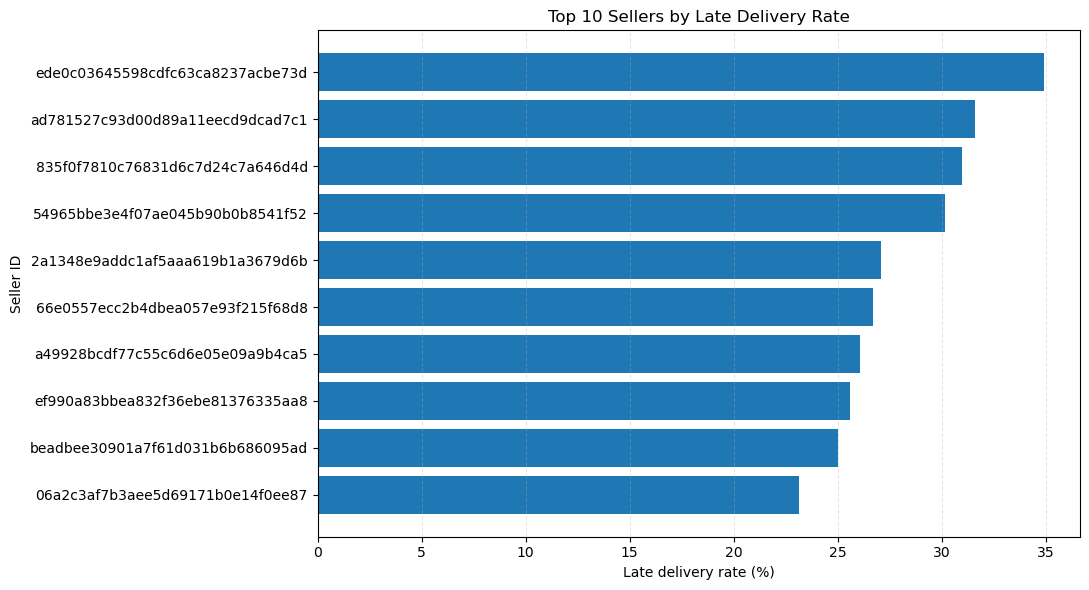

In [36]:
top_10 = (
    top_late_sellers.head(10)
    .sort_values("late_rate_pct")
)

plt.figure(figsize=(11, 6))
plt.barh(
    top_10["seller_id"],
    top_10["late_rate_pct"]
)

plt.xlabel("Late delivery rate (%)")
plt.ylabel("Seller ID")
plt.title("Top 10 Sellers by Late Delivery Rate")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [40]:
import duckdb

con = duckdb.connect("supply_chain_analytics.duckdb")

print("DuckDB connection successful!")

DuckDB connection successful!


In [45]:
con.register("orders_df", orders_clean)
con.register("customers_df", customers)
con.register("items_df", order_items)
con.register("sellers_df", sellers)

con.execute("""
CREATE OR REPLACE TABLE orders AS
SELECT * FROM orders_df
""")

con.execute("""
CREATE OR REPLACE TABLE customers AS
SELECT * FROM customers_df
""")

con.execute("""
CREATE OR REPLACE TABLE order_items AS
SELECT * FROM items_df
""")

con.execute("""
CREATE OR REPLACE TABLE sellers AS
SELECT * FROM sellers_df
""")

print("Tables created successfully!")

Tables created successfully!


In [48]:
regional_sql = con.execute("""
SELECT
    c.customer_state,
    COUNT(DISTINCT o.order_id) AS total_orders,
    COUNT(DISTINCT CASE
        WHEN o.order_delivered_customer_date
             > o.order_estimated_delivery_date
        THEN o.order_id
    END) AS late_orders,
    ROUND(
        100.0 * COUNT(DISTINCT CASE
            WHEN o.order_delivered_customer_date
                 > o.order_estimated_delivery_date
            THEN o.order_id
        END) / COUNT(DISTINCT o.order_id),
        2
    ) AS late_rate_pct
FROM orders o
JOIN customers c
    ON o.customer_id = c.customer_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND o.order_estimated_delivery_date IS NOT NULL
GROUP BY c.customer_state
ORDER BY late_rate_pct DESC
""").df()

display(regional_sql.head(10))

,customer_state,total_orders,late_orders,late_rate_pct
0,AL,397,95,23.93
1,MA,717,141,19.67
2,PI,476,76,15.97
3,CE,1279,196,15.32
4,SE,335,51,15.22
5,BA,3256,457,14.04
6,RJ,12350,1664,13.47
7,TO,274,35,12.77
8,PA,946,117,12.37
9,ES,1995,244,12.23


In [50]:
monthly_sql = con.execute("""
WITH delivered_orders AS (
    SELECT
        order_id,
        DATE_TRUNC(
            'month',
            order_purchase_timestamp
        ) AS order_month,
        CASE
            WHEN order_delivered_customer_date
                 > order_estimated_delivery_date
            THEN 1
            ELSE 0
        END AS is_late,
        DATE_DIFF(
            'day',
            order_purchase_timestamp,
            order_delivered_customer_date
        ) AS delivery_days
    FROM orders
    WHERE order_status = 'delivered'
      AND order_delivered_customer_date IS NOT NULL
      AND order_estimated_delivery_date IS NOT NULL
)
SELECT
    order_month,
    COUNT(*) AS total_orders,
    SUM(is_late) AS late_orders,
    ROUND(100.0 * AVG(is_late), 2) AS late_rate_pct,
    ROUND(AVG(delivery_days), 2) AS avg_delivery_days
FROM delivered_orders
GROUP BY order_month
ORDER BY order_month
""").df()

display(monthly_sql.head(10))

,order_month,total_orders,late_orders,late_rate_pct,avg_delivery_days
0,2016-09-01,1,1.0,100.00,55.00
1,2016-10-01,265,3.0,1.13,19.63
2,2016-12-01,1,0.0,0.00,5.00
3,2017-01-01,750,23.0,3.07,12.75
4,2017-02-01,1653,53.0,3.21,13.30
5,2017-03-01,2546,142.0,5.58,13.04
6,2017-04-01,2303,181.0,7.86,15.02
7,2017-05-01,3545,128.0,3.61,11.43
8,2017-06-01,3135,121.0,3.86,12.01
9,2017-07-01,3872,133.0,3.43,11.49


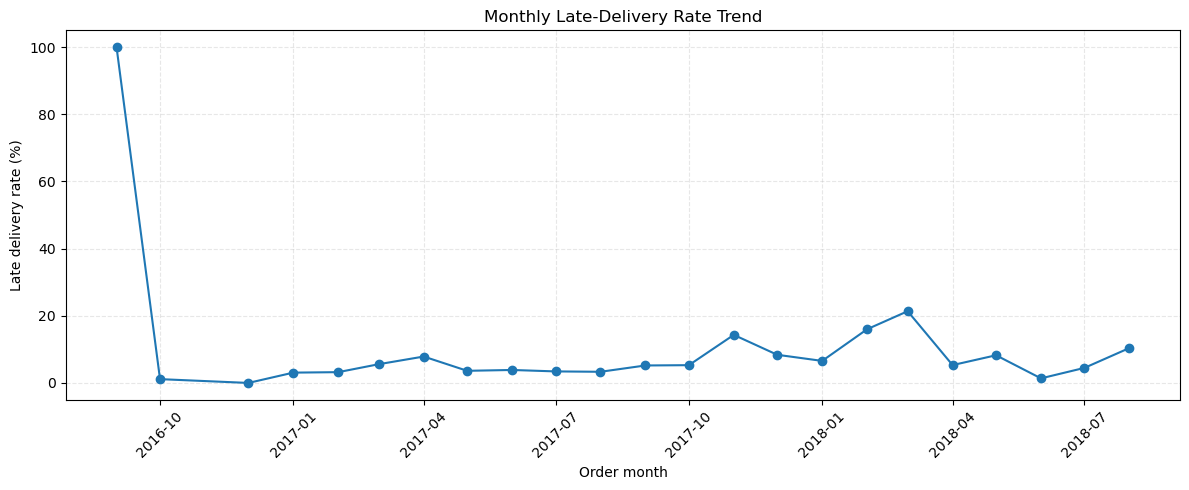

In [52]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sql["order_month"],
    monthly_sql["late_rate_pct"],
    marker="o"
)

plt.xlabel("Order month")
plt.ylabel("Late delivery rate (%)")
plt.title("Monthly Late-Delivery Rate Trend")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [54]:
print(monthly_sql.columns.tolist())
display(monthly_sql.head(10).to_string(index=False))

['order_month', 'total_orders', 'late_orders', 'late_rate_pct', 'avg_delivery_days']


'order_month  total_orders  late_orders  late_rate_pct  avg_delivery_days\n 2016-09-01             1          1.0         100.00              55.00\n 2016-10-01           265          3.0           1.13              19.63\n 2016-12-01             1          0.0           0.00               5.00\n 2017-01-01           750         23.0           3.07              12.75\n 2017-02-01          1653         53.0           3.21              13.30\n 2017-03-01          2546        142.0           5.58              13.04\n 2017-04-01          2303        181.0           7.86              15.02\n 2017-05-01          3545        128.0           3.61              11.43\n 2017-06-01          3135        121.0           3.86              12.01\n 2017-07-01          3872        133.0           3.43              11.49'

In [58]:
monthly_reliable = monthly_sql[
    monthly_sql["total_orders"] >= 100
].copy()

display(monthly_reliable.head(10))

,order_month,total_orders,late_orders,late_rate_pct,avg_delivery_days
1,2016-10-01,265,3.0,1.13,19.63
3,2017-01-01,750,23.0,3.07,12.75
4,2017-02-01,1653,53.0,3.21,13.30
5,2017-03-01,2546,142.0,5.58,13.04
6,2017-04-01,2303,181.0,7.86,15.02
7,2017-05-01,3545,128.0,3.61,11.43
8,2017-06-01,3135,121.0,3.86,12.01
9,2017-07-01,3872,133.0,3.43,11.49
10,2017-08-01,4193,139.0,3.32,11.02
11,2017-09-01,4150,216.0,5.20,11.72


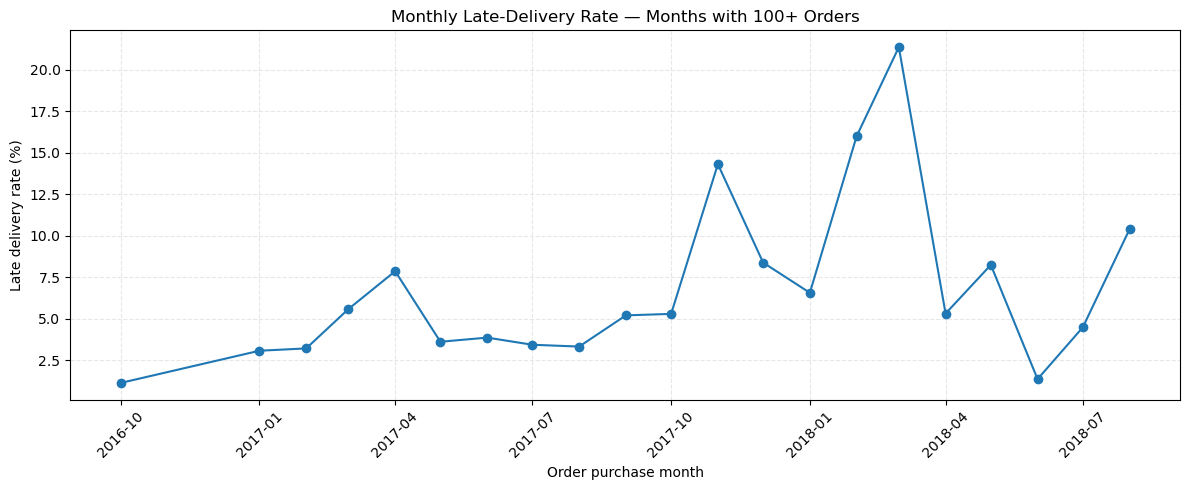

In [60]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_reliable["order_month"],
    monthly_reliable["late_rate_pct"],
    marker="o"
)

plt.xlabel("Order purchase month")
plt.ylabel("Late delivery rate (%)")
plt.title("Monthly Late-Delivery Rate — Months with 100+ Orders")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [56]:
geography_sql = con.execute("""
WITH order_seller_pairs AS (
    SELECT DISTINCT
        oi.order_id,
        oi.seller_id
    FROM order_items oi
),
delivery_data AS (
    SELECT
        o.order_id,
        c.customer_state,
        s.seller_state,
        CASE
            WHEN o.order_delivered_customer_date
                 > o.order_estimated_delivery_date
            THEN 1
            ELSE 0
        END AS is_late,
        DATE_DIFF(
            'day',
            o.order_purchase_timestamp,
            o.order_delivered_customer_date
        ) AS delivery_days
    FROM orders o
    JOIN customers c
        ON o.customer_id = c.customer_id
    JOIN order_seller_pairs p
        ON o.order_id = p.order_id
    JOIN sellers s
        ON p.seller_id = s.seller_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_estimated_delivery_date IS NOT NULL
)
SELECT
    seller_state,
    customer_state,
    COUNT(DISTINCT order_id) AS total_orders,
    COUNT(DISTINCT CASE
        WHEN is_late = 1 THEN order_id
    END) AS late_orders,
    ROUND(
        100.0 * COUNT(DISTINCT CASE
            WHEN is_late = 1 THEN order_id
        END) / COUNT(DISTINCT order_id),
        2
    ) AS late_rate_pct,
    ROUND(AVG(delivery_days), 2) AS avg_delivery_days
FROM delivery_data
GROUP BY seller_state, customer_state
HAVING COUNT(DISTINCT order_id) >= 100
ORDER BY late_rate_pct DESC
""").df()

display(geography_sql.head(15))

,seller_state,customer_state,total_orders,late_orders,late_rate_pct,avg_delivery_days
0,SP,AL,256,67,26.17,24.94
1,MA,SP,124,31,25.00,15.98
2,SP,MA,493,105,21.30,22.01
3,SP,PI,329,60,18.24,20.24
4,PR,BA,144,24,16.67,21.81
5,SP,SE,208,34,16.35,21.19
6,SP,RJ,8188,1264,15.44,16.14
7,SP,CE,970,148,15.26,21.13
8,SP,BA,2313,345,14.92,19.68
9,SP,MS,478,70,14.64,15.82


In [62]:

# Create a one-row-per-order analysis table
powerbi_orders = delivered[
    [
        "order_id",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "delivery_time_days",
        "delay_days",
        "delivery_performance"
    ]
].copy()

# Add customer state
powerbi_orders = powerbi_orders.merge(
    customers[["customer_id", "customer_state"]],
    left_on="order_id",
    right_on="order_id",
    how="left"
) if "customer_id" in powerbi_orders.columns else powerbi_orders

# Safer approach: add customer_id from the original orders table
if "customer_state" not in powerbi_orders.columns:
    powerbi_orders = powerbi_orders.merge(
        orders_clean[["order_id", "customer_id"]],
        on="order_id",
        how="left",
        validate="one_to_one"
    )
    powerbi_orders = powerbi_orders.merge(
        customers[["customer_id", "customer_state"]],
        on="customer_id",
        how="left",
        validate="many_to_one"
    )

# Create a purchase month column
powerbi_orders["order_month"] = (
    pd.to_datetime(powerbi_orders["order_purchase_timestamp"])
    .dt.to_period("M").astype(str)
)

# Export CSV
powerbi_orders.to_csv(
    "powerbi_delivery_orders.csv",
    index=False
)

print("Export rows:", len(powerbi_orders))
print("Export columns:", powerbi_orders.columns.tolist())
print("File saved: powerbi_delivery_orders.csv")

Export rows: 96470
Export columns: ['order_id', 'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'delivery_time_days', 'delay_days', 'delivery_performance', 'customer_id', 'customer_state', 'order_month']
File saved: powerbi_delivery_orders.csv
